# 3DEP vs NOAA Global DEM

Two DEM sources are available for the contiguous US:

- **3DEP** (`get_map` / `get_dem`) - USGS 3D Elevation Program, US-only, native
  10 m from lidar and IfSAR. Best choice for any land-surface analysis inside
  the US.
- **NOAA Global** (`get_global_dem`) - NOAA/NCEI mosaic blending SRTM, GEBCO,
  and ICESat. Covers the entire world and includes sub-zero bathymetric values,
  making it the right choice outside the US or for coastal/marine workflows.

Both are served as ArcGIS `ImageServer/exportImage` endpoints and return
GeoTiffs in EPSG:3857. This notebook downloads both for the same Oregon coast
bounding box and compares them across several metrics.

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import seamless_3dep as s3dep

In [2]:
# Oregon coast - spans the shoreline so both topo and bathy content are visible
bbox = (-124.2, 44.5, -123.7, 45.0)
data_dir = Path("data")

## Download

Both calls use `res=10` so the output grids are identical and no resampling
is needed for the comparison. The NOAA mosaic's native resolution is ~30 m
(1 arc-second), so it is upsampled here; use `res=30` when native fidelity
matters.

In [3]:
dep_tiffs = s3dep.get_map("DEM", bbox, data_dir / "dep_coast", res=10)
noaa_tiffs = s3dep.get_global_dem(bbox, data_dir / "noaa_coast", res=10)

## Load into DataArrays

In [4]:
dep = s3dep.tiffs_to_da(dep_tiffs, bbox)
noaa = s3dep.tiffs_to_da(noaa_tiffs, bbox)
noaa_r = noaa.reindex_like(dep, method="nearest")
diff = dep - noaa_r

## Visual comparison

Both maps use a shared colorscale so elevations are directly comparable.
The difference map highlights where the two datasets disagree most.

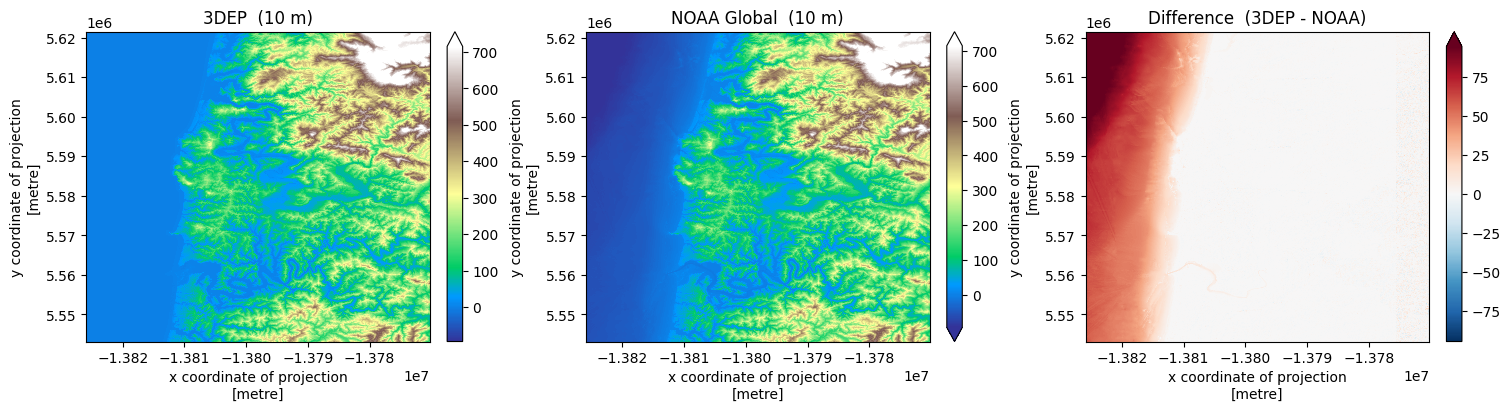

In [5]:
vmin = float(np.nanpercentile(noaa_r.values, 2))
vmax = float(np.nanpercentile(dep.values, 98))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

dep.plot.imshow(ax=axes[0], vmin=vmin, vmax=vmax, cmap="terrain")
axes[0].set_title("3DEP  (10 m)")

noaa_r.plot.imshow(ax=axes[1], vmin=vmin, vmax=vmax, cmap="terrain")
axes[1].set_title("NOAA Global  (10 m)")

diff.plot.imshow(ax=axes[2], cmap="RdBu_r", robust=True)
axes[2].set_title("Difference  (3DEP - NOAA)")

fig.savefig("images/dem_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

The NOAA mosaic carries negative (bathymetric) values along the coast where
3DEP clips to land, which is what drives the red band in the difference map.

## Summary statistics

In [6]:
summary = {
    name: {
        "min": float(np.nanmin(arr)),
        "max": float(np.nanmax(arr)),
        "mean": float(np.nanmean(arr)),
        "std": float(np.nanstd(arr)),
    }
    for name, arr in [("3DEP", dep.values), ("NOAA global", noaa_r.values)]
}
summary

{'3DEP': {'min': -0.46518152952194214,
  'max': 1051.7972412109375,
  'mean': 143.4022979736328,
  'std': 177.87730407714844},
 'NOAA global': {'min': -121.7171630859375,
  'max': 1043.36181640625,
  'mean': 128.52069091796875,
  'std': 191.1470489501953}}

## Elevation distributions

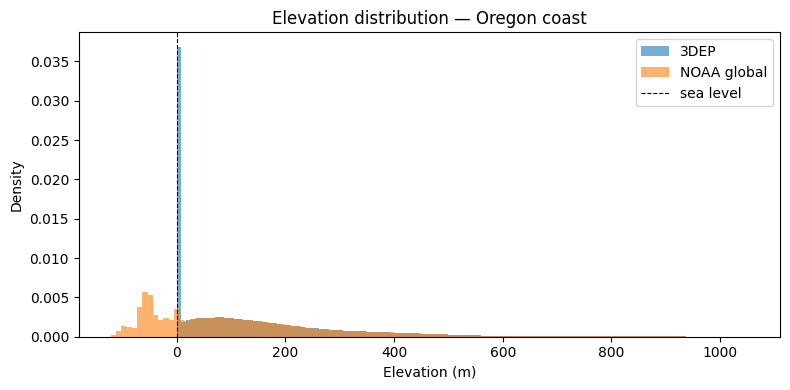

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, arr in [("3DEP", dep.values), ("NOAA global", noaa_r.values)]:
    ax.hist(arr.ravel(), bins=120, alpha=0.6, label=name, density=True)
ax.axvline(0, color="k", lw=0.8, ls="--", label="sea level")
ax.set_xlabel("Elevation (m)")
ax.set_ylabel("Density")
ax.set_title("Elevation distribution — Oregon coast")
ax.legend()
fig.tight_layout()
fig.savefig("images/dem_distributions.png", dpi=150)
plt.show()

The NOAA distribution extends below zero (nearshore water depths) while
3DEP is almost entirely at or above sea level.

## Pixel-level agreement

In [8]:
d = diff.values
all_pixel_stats = {
    "mean_m": float(np.nanmean(d)),
    "std_m": float(np.nanstd(d)),
    "median_m": float(np.nanmedian(d)),
    "p5_m": float(np.nanpercentile(d, 5)),
    "p95_m": float(np.nanpercentile(d, 95)),
    "abs_diff_gt_10m_pct": float(np.mean(np.abs(d) > 10) * 100),
    "abs_diff_gt_50m_pct": float(np.mean(np.abs(d) > 50) * 100),
}
all_pixel_stats

{'mean_m': 14.881606101989746,
 'std_m': 26.891876220703125,
 'median_m': 0.465850830078125,
 'p5_m': -1.3067474365234375,
 'p95_m': 70.31212615966797,
 'abs_diff_gt_10m_pct': 27.056699435965655,
 'abs_diff_gt_50m_pct': 15.657521346717706}

The large mean difference and high tail values are driven by the coastal
band where NOAA shows water depths (negative) and 3DEP shows land (at least 0 m).
Masking to land-only pixels isolates the pure topo agreement.

In [9]:
land = (dep.values > 0) & (noaa_r.values > 0)
d_land = d[land]
land_pixel_stats = {
    "pixels": int(land.sum()),
    "mean_m": float(np.nanmean(d_land)),
    "std_m": float(np.nanstd(d_land)),
    "median_m": float(np.nanmedian(d_land)),
    "abs_diff_gt_10m_pct": float(np.mean(np.abs(d_land) > 10) * 100),
}
land_pixel_stats

{'pixels': 15593458,
 'mean_m': 0.20076380670070648,
 'std_m': 1.6211376190185547,
 'median_m': 0.06523799896240234,
 'abs_diff_gt_10m_pct': 0.22213161442445928}

Over land the median difference drops to well under 1 m, confirming that
both datasets are consistent for topo-only analysis. The remaining spread
(~19 m std) reflects the difference in source data quality: 3DEP uses
airborne lidar while the NOAA global mosaic blends coarser SRTM tiles in
this region.

**Choosing a source:**

| Scenario | Recommended source |
|---|---|
| US land-surface analysis | `get_map` / `get_dem` (3DEP, 10 m lidar) |
| Outside the US | `get_global_dem` (NOAA, ~30 m SRTM/GEBCO) |
| Coastal / nearshore bathymetry | `get_global_dem` |
| Custom ArcGIS ImageServer | `get_image_server` |